# 05. Previsões com o modelo vigente e teste integrado

1. Carrega o vigente pelo MLflow. O objeto salvo é o Pipeline inteiro (imputação, padronização e modelo) e a lista de features vem do manifesto, então a previsão usa o mesmo pré-processamento do treino.
2. **Avaliação final no teste:** os 30 dias mais recentes com alvo conhecido. Eles não entraram na votação, na escolha entre A e B nem na promoção.
3. **Previsão do dia seguinte** ao último dia com dado, que na execução agendada é o próprio dia da execução: os dias que o ERA5 ainda não publicou entram como dado provisório (notebook 01). Ela fica registrada em `evidencias/previsoes_diarias.csv` e é conferida com o ERA5 nos ciclos seguintes, quando o dado real chega.
4. **Teste integrado:** confere no MLflow que este ciclo refez a votação, treinou A e B com as mesmas features e registrou a decisão de promoção, tudo com o mesmo `cycle_id` e `data_version`.
5. **Comparação com o ciclo anterior:** o que mudou de um ciclo para o outro.

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
from src import ciclo, modelagem, preprocessamento, promocao

cfg = ciclo.carregar_config()
estado = ciclo.atual()
mlflow = ciclo.configurar_mlflow(cfg)
dataset, janelas = preprocessamento.carregar(cfg)
pd.set_option("display.precision", 3)
print(f"ciclo {estado['cycle_id']} | {estado['data_version']}")
import matplotlib.pyplot as plt

ciclo 20261109-184535 | dv-20261102-97fa6541


In [2]:
manifesto = promocao.ler_manifesto()
if manifesto is None:
    raise RuntimeError("não há modelo vigente para prever")
modelo = mlflow.sklearn.load_model(manifesto["model_uri"])
feats = manifesto["features"]
print(f"vigente: {manifesto['algoritmo']}, promovido no ciclo {manifesto['cycle_id']} ({manifesto['data_version']})")
print("features:", ", ".join(feats))
print(modelo)

vigente: hist_gradient_boosting, promovido no ciclo 20261107-205440 (dv-20261024-622a2671)
features: tmed, dia_ano_cos, tmin, radiacao, vento_dir_cos, tmax, pressao_delta, rajada
Pipeline(steps=[('imputacao', SimpleImputer(strategy='median')),
                ('escala', StandardScaler()),
                ('modelo',
                 HistGradientBoostingRegressor(l2_regularization=1.0,
                                               learning_rate=0.05, max_iter=300,
                                               max_leaf_nodes=15,
                                               random_state=42))])


## Avaliação final no teste

In [3]:
teste = janelas["teste"]
previsoes = pd.DataFrame({"data_base": teste.index, "real": teste.alvo.to_numpy(), "previsto": modelo.predict(teste[feats]),
                          "persistencia": teste.tmax.to_numpy()}, index=(teste.index + pd.Timedelta(days=1)).rename("data_alvo"))
m_teste = modelagem.metricas(previsoes.real, previsoes.previsto)
m_pers = modelagem.metricas(previsoes.real, previsoes.persistencia)
pd.DataFrame({"vigente": m_teste, "persistência": m_pers}).T

,mae,rmse,r2
vigente,2.288,2.810,0.039
persistência,2.397,2.954,-0.063


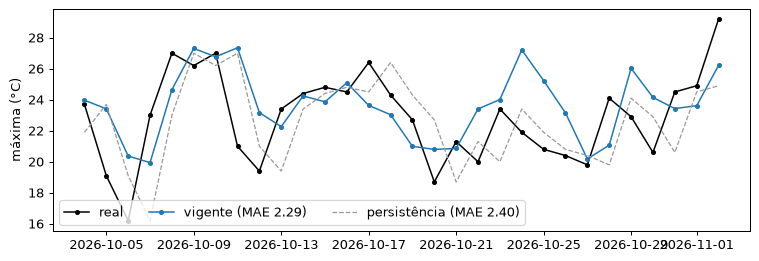

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.2), dpi=90)
ax.plot(previsoes.index, previsoes.real, "k-o", ms=3, lw=1.2, label="real")
ax.plot(previsoes.index, previsoes.previsto, "-o", color="tab:blue", ms=3, lw=1.2, label=f"vigente (MAE {m_teste['mae']:.2f})")
ax.plot(previsoes.index, previsoes.persistencia, "--", color="0.6", lw=1, label=f"persistência (MAE {m_pers['mae']:.2f})")
ax.set_ylabel("máxima (°C)")
ax.legend(loc="lower left", ncols=3)
plt.show()

## Previsão do dia seguinte e conferência das previsões antigas

In [5]:
proximo = janelas["proximo"]
data_alvo = proximo.index[0] + pd.Timedelta(days=1)
valor = float(modelo.predict(proximo[feats])[0])
print(f"máxima prevista para {data_alvo:%d/%m/%Y}: {valor:.1f} °C (com dados até {proximo.index[0]:%d/%m/%Y})")

arquivo = ciclo.EVIDENCIAS / "previsoes_diarias.csv"
registro = pd.read_csv(arquivo, parse_dates=["data_alvo", "data_base"]) if arquivo.exists() else pd.DataFrame()
nova = pd.DataFrame([{"data_alvo": data_alvo, "data_base": proximo.index[0], "previsto": round(valor, 2),
                      "cycle_id": estado["cycle_id"], "modelo": f"{manifesto['algoritmo']} ({manifesto['cycle_id']})"}])
registro = pd.concat([registro, nova], ignore_index=True).drop_duplicates("data_alvo", keep="last").sort_values("data_alvo")
registro["real"] = registro.data_alvo.map(dataset.tmax)
registro["erro"] = (registro.previsto - registro.real).round(2)
registro.to_csv(arquivo, index=False)
registro.tail(10)

máxima prevista para 09/11/2026: 23.7 °C (com dados até 08/11/2026)


,data_alvo,data_base,previsto,cycle_id,modelo,real,erro
0,2026-10-25,2026-10-24,25.23,20261107-205440,hist_gradient_boosting (20261107-205440),20.8,4.43
1,2026-11-01,2026-10-31,23.61,20261107-205914,hist_gradient_boosting (20261107-205440),24.9,-1.29
2,2026-11-02,2026-11-01,26.21,20261108-170654,hist_gradient_boosting (20261107-205440),29.2,-2.99
3,2026-11-09,2026-11-08,23.73,20261109-184535,hist_gradient_boosting (20261107-205440),NaN,NaN


## Teste integrado do ciclo

In [6]:
runs = mlflow.search_runs(filter_string=f"tags.cycle_id = '{estado['cycle_id']}'")
treinos = runs[runs["tags.etapa"] == "treino"]
assert {"votacao", "treino", "decisao"} <= set(runs["tags.etapa"]), "faltou etapa no MLflow"
assert sorted(treinos["tags.papel"]) == ["A", "B"], "os dois algoritmos precisam ter sido treinados"
assert treinos["params.features"].nunique() == 1, "A e B precisam usar as mesmas features"
assert treinos["params.features"].iloc[0] == ",".join(estado["votacao"]["features"]), "features diferentes das eleitas"
assert set(runs["tags.data_version"]) == {estado["data_version"]}, "data_version diferente entre as etapas"
assert manifesto["ultima_decisao"]["cycle_id"] == estado["cycle_id"], "a decisão deste ciclo não está no manifesto"
print(f"ok: votação refeita, A e B treinados com as mesmas {len(estado['votacao']['features'])} features, "
      f"modelo {manifesto['ultima_decisao']['decisao']} automaticamente")
runs[["tags.etapa", "tags.papel", "tags.algoritmo", "tags.decisao", "run_id", "metrics.mae_validacao"]]

ok: votação refeita, A e B treinados com as mesmas 8 features, modelo mantido automaticamente


,tags.etapa,tags.papel,tags.algoritmo,tags.decisao,run_id,metrics.mae_validacao
0,decisao,NaN,NaN,mantido,5d0fb8e10742435b9a293ace49b5803f,NaN
1,treino,B,hist_gradient_boosting,NaN,08af57b0147d4ee3bfd8654bb3275d03,1.888
2,treino,A,ridge,NaN,ca6d04de4e9d4bc9ba1ebd72965027ac,1.941
3,votacao,NaN,NaN,NaN,3763a59e244f47478971606ebf29fe5d,NaN


## O que mudou em relação ao ciclo anterior

In [7]:
hist = ciclo.historico()
hist = hist[hist["cycle_id"].le(estado["cycle_id"]) & hist["votacao.features"].notna()]
if len(hist) > 1:
    antes, agora = hist.iloc[-2], hist.iloc[-1]
    entraram = sorted(set(agora["votacao.features"]) - set(antes["votacao.features"]))
    sairam = sorted(set(antes["votacao.features"]) - set(agora["votacao.features"]))
    print(f"ciclo anterior {antes['cycle_id']} -> atual {agora['cycle_id']}")
    print(f"dados: até {antes['dados.fim']} -> até {agora['dados.fim']} (+{agora['dados.linhas'] - antes['dados.linhas']} dias)")
    print(f"data_version: {antes['data_version']} -> {agora['data_version']}")
    print(f"features: entraram {entraram or 'nenhuma'}, saíram {sairam or 'nenhuma'}")
else:
    print("primeiro ciclo: ainda não há ciclo anterior para comparar")
colunas = ["cycle_id", "evento", "data_version", "dados.fim", "lote.n_novos", "votacao.n",
           "competicao.A.validacao.mae", "competicao.B.validacao.mae", "decisao.vencedor", "decisao.decisao"]
hist[[c for c in colunas if c in hist]].tail(5)

ciclo anterior 20261108-170654 -> atual 20261109-184535
dados: até 2026-11-01 -> até 2026-11-02 (+1 dias)
data_version: dv-20261101-158b26fd -> dv-20261102-97fa6541
features: entraram nenhuma, saíram nenhuma


,cycle_id,evento,data_version,dados.fim,lote.n_novos,votacao.n,competicao.A.validacao.mae,competicao.B.validacao.mae,decisao.vencedor,decisao.decisao
0,20261107-205440,workflow_dispatch,dv-20261024-622a2671,2026-10-24,6141,8,1.929,1.887,B,promovido
1,20261107-205914,workflow_dispatch,dv-20261031-5975bc1e,2026-10-31,7,8,1.933,1.867,B,mantido
2,20261108-170654,schedule,dv-20261101-158b26fd,2026-11-01,1,8,1.945,1.897,B,mantido
3,20261109-184535,workflow_dispatch,dv-20261102-97fa6541,2026-11-02,1,8,1.941,1.888,B,mantido


In [8]:
arquivo_teste = ciclo.pasta(estado) / "previsoes_teste.csv"
previsoes.to_csv(arquivo_teste)
with mlflow.start_run(run_name=f"{estado['cycle_id']}-previsoes", tags=ciclo.tags(estado, "previsoes")) as run:
    mlflow.log_params({"model_uri": manifesto["model_uri"], "vigente_cycle_id": manifesto["cycle_id"],
                       "data_alvo": str(data_alvo.date())})
    mlflow.log_metrics({f"{k}_teste": v for k, v in m_teste.items()}
                       | {"mae_persistencia_teste": m_pers["mae"], "previsao_dia_seguinte": valor})
    mlflow.log_artifact(arquivo_teste)

estado["previsoes"] = {"run_id": run.info.run_id, "mae_teste": m_teste["mae"], "mae_persistencia_teste": m_pers["mae"],
                       "dias_teste": len(teste), "data_alvo": str(data_alvo.date()), "previsto": round(valor, 2)}
ciclo.salvar(estado)